In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

# Assumes the notebook kernel is running from DeepVisionLab/.
PROJECT_DIR = Path.cwd()
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def save_figure(fig, name):
    """PNG for sharing; vector PDF for reports."""
    fig.savefig(
        FIGURES_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        FIGURES_DIR / f"{name}.pdf",
        bbox_inches="tight",
        facecolor="white",
    )

def save_results(name, data):
    with open(RESULTS_DIR / f"{name}.json", "w") as f:
        json.dump(data, f, indent=2)

print("Figures:", FIGURES_DIR)
print("Results:", RESULTS_DIR)

Figures: /home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/figures
Results: /home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/results


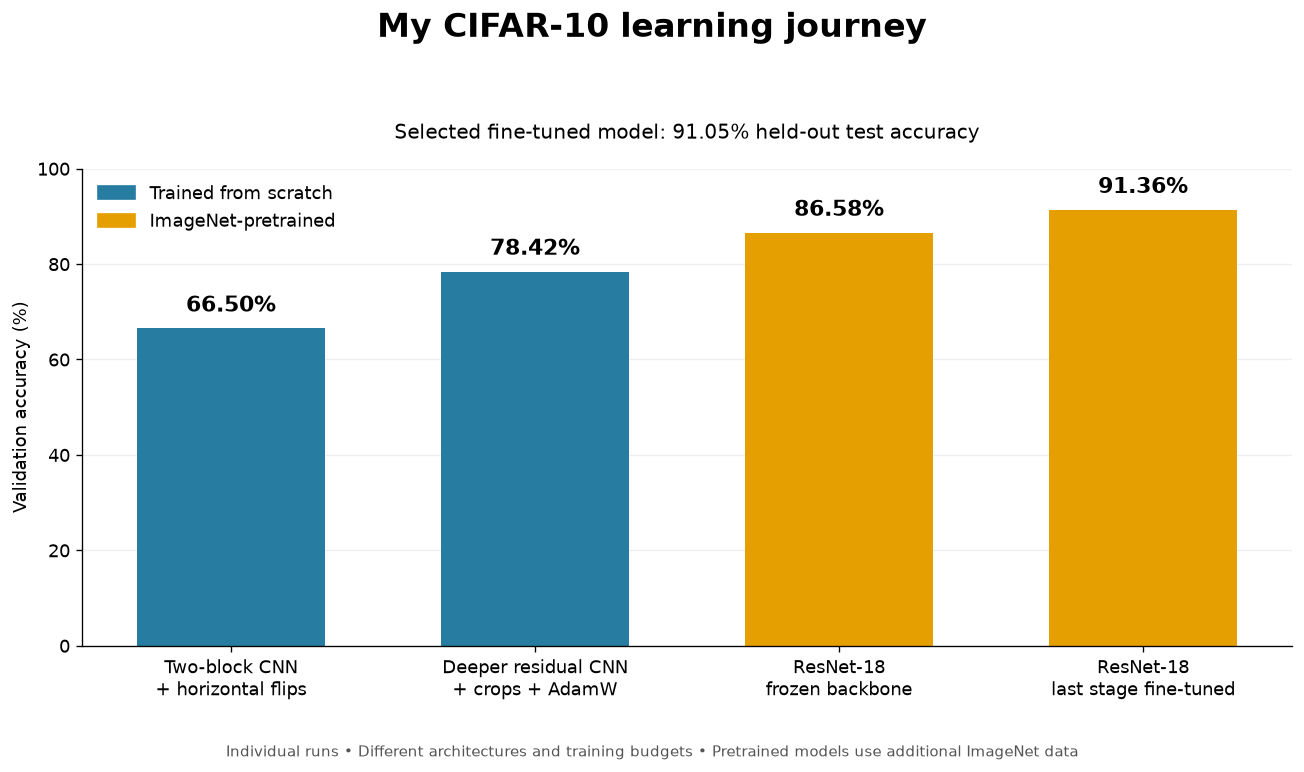

In [2]:
progress = [
    {
        "name": "Two-block CNN\n+ horizontal flips",
        "validation_accuracy": 66.50,
        "pretrained": False,
    },
    {
        "name": "Deeper residual CNN\n+ crops + AdamW",
        "validation_accuracy": 78.42,
        "pretrained": False,
    },
    {
        "name": "ResNet-18\nfrozen backbone",
        "validation_accuracy": 86.58,
        "pretrained": True,
    },
    {
        "name": "ResNet-18\nlast stage fine-tuned",
        "validation_accuracy": 91.36,
        "pretrained": True,
    },
]

save_results("classification_progress", {
    "experiments": progress,
    "selected_transfer_model_test_accuracy": 91.05,
    "note": (
        "Individual experiments with different architectures, training "
        "budgets, and preprocessing; not a controlled ablation."
    ),
})

colors = [
    "#277DA1" if not row["pretrained"] else "#E69F00"
    for row in progress
]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    range(len(progress)),
    [row["validation_accuracy"] for row in progress],
    color=colors,
    width=0.62,
)

ax.bar_label(
    bars,
    labels=[
        f"{row['validation_accuracy']:.2f}%"
        for row in progress
    ],
    padding=7,
    fontsize=13,
    fontweight="bold",
)

ax.set_xticks(
    range(len(progress)),
    [row["name"] for row in progress],
)
ax.set_ylim(0, 100)
ax.set_ylabel("Validation accuracy (%)")
ax.grid(axis="y", alpha=0.2)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#277DA1", label="Trained from scratch"),
        Patch(color="#E69F00", label="ImageNet-pretrained"),
    ],
    loc="upper left",
    frameon=False,
)

fig.suptitle(
    "My CIFAR-10 learning journey",
    fontsize=20,
    fontweight="bold",
    y=0.98,
)
ax.set_title(
    "Selected fine-tuned model: 91.05% held-out test accuracy",
    fontsize=12,
    pad=18,
)

fig.text(
    0.5, 0.025,
    "Individual runs • Different architectures and training budgets • "
    "Pretrained models use additional ImageNet data",
    ha="center",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.07, 1, 0.93])
save_figure(fig, "classification_progress")
plt.show()

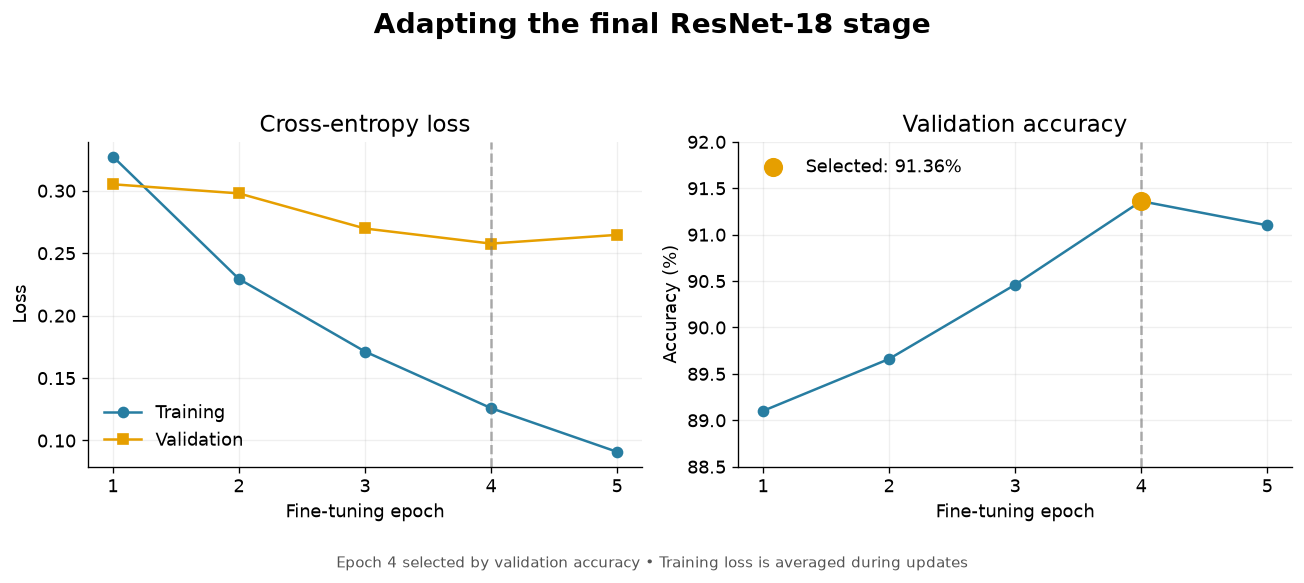

In [3]:
finetune_history = {
    "epoch": [1, 2, 3, 4, 5],
    "train_loss": [0.3273, 0.2293, 0.1712, 0.1259, 0.0909],
    "val_loss": [0.3051, 0.2978, 0.2697, 0.2576, 0.2646],
    "val_accuracy": [89.10, 89.66, 90.46, 91.36, 91.10],
    "selected_epoch": 4,
    "source": "Recorded notebook output, rounded to displayed precision",
}

save_results("resnet18_finetuning_history", finetune_history)

epochs = finetune_history["epoch"]
selected_epoch = finetune_history["selected_epoch"]
selected_index = epochs.index(selected_epoch)

fig, axes = plt.subplots(figsize=(11, 4.8), ncols=2)

axes[0].plot(
    epochs,
    finetune_history["train_loss"],
    marker="o",
    color="#277DA1",
    label="Training",
)
axes[0].plot(
    epochs,
    finetune_history["val_loss"],
    marker="s",
    color="#E69F00",
    label="Validation",
)
axes[0].set_title("Cross-entropy loss")
axes[0].set_ylabel("Loss")
axes[0].legend(frameon=False)

axes[1].plot(
    epochs,
    finetune_history["val_accuracy"],
    marker="o",
    color="#277DA1",
)
axes[1].scatter(
    [selected_epoch],
    [finetune_history["val_accuracy"][selected_index]],
    color="#E69F00",
    s=110,
    zorder=3,
    label="Selected: 91.36%",
)
axes[1].set_title("Validation accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(88.5, 92)
axes[1].legend(frameon=False)

for ax in axes:
    ax.axvline(
        selected_epoch,
        color="#777777",
        linestyle="--",
        alpha=0.6,
    )
    ax.set_xlabel("Fine-tuning epoch")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.2)

fig.suptitle(
    "Adapting the final ResNet-18 stage",
    fontsize=17,
    fontweight="bold",
)
fig.text(
    0.5, 0.015,
    "Epoch 4 selected by validation accuracy • "
    "Training loss is averaged during updates",
    ha="center",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0, 0.06, 1, 0.92])
save_figure(fig, "resnet18_finetuning_curves")
plt.show()